# Philippine inflation forecasting: model review
**Notebook-only progress demonstration.** Run all cells in order with the project's `.venv` Python kernel. Plots, tables, fitted results and interpretations are saved inside this notebook. No web app or database is required.

**Question:** Do lagged exchange rates, the policy rate and M3 growth improve one-, two- and three-month Philippine headline inflation forecasts compared with simple benchmarks and SARIMA?

**Audience:** the student researchers, instructor and evaluators. Intended analytical users include students, researchers and people examining Philippine economic trends. This is an academic estimate, not an official forecast or a causal study.

The supplied midterm rubric asks for dataset understanding, justified preparation, explained algorithms and meaningful comparisons, actual evaluation results, executable evidence, and individual understanding. The sections below provide that evidence; they do not claim a rubric score.

**Review boundary:** retain the existing eight-candidate experiment. Its final 24-month block has already been inspected in an earlier prototype. It is reported honestly as a *previously evaluated holdout*, not a newly untouched test. Do not tune against it in this review. Further tuning needs a new assessment design or newly arriving observations.

In [1]:
# MODEL_REVIEW_VERSION = 1
from pathlib import Path
import sys, json, hashlib, warnings
import importlib.metadata as import_metadata
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.gofplots import qqplot
from statsmodels.tools.sm_exceptions import ConvergenceWarning
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
OUT=ROOT/'artifacts/model_review'
OUT.mkdir(parents=True,exist_ok=True)
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110,'savefig.dpi':150,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
    'font.size':10,'axes.titlesize':12,'axes.titleweight':'bold'})
COLORS=['#126a88','#d27c2c','#29815e','#8b61a8']
def show_plot(fig,name):
    fig.tight_layout()
    fig.savefig(OUT/(name+'.png'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
display(pd.DataFrame({'package':['pandas','numpy','statsmodels','matplotlib'],
    'version':[import_metadata.version(p) for p in ['pandas','numpy','statsmodels','matplotlib']]}))
print('Kernel:',sys.executable)
print('Review exports:',OUT)

,package,version
0,pandas,3.1.0
1,numpy,2.5.4
2,statsmodels,0.15.0
3,matplotlib,3.11.2


Kernel: C:\Users\Luzan\Documents\Elec 4\.venv\Scripts\python.exe
Review exports: C:\Users\Luzan\Documents\Elec 4\artifacts\model_review


## 1. Source understanding and preparation audit
**Grain:** one national reference month in the analytical table; each underlying observation is one indicator, geography, reference month and supplied-file vintage.

| Series | Source file | Meaning and treatment |
|---|---|---|
| Inflation | two PSA-style CSV exports | National all-items year-on-year percent, both labeled 2018=100; concatenate without recalculating inflation |
| PHP/USD | pesodollar.xlsx | Use monthly average, not end-of-period rate |
| Policy rate | MonetaryPolicyDecisions.xlsx | Extract the first numeric policy-rate clause; last decision per month, then forward-fill known decisions |
| M3 | dcs_srf.xlsx, level row 25 | Million PHP; parse revision/provisional date suffixes, then derive 12-month growth |

The raw files are user-supplied and are not independently authenticated here. Original publication dates and release vintages are absent. Five nonnumeric 2011 hold decisions, exact policy effective dates and the 2016 policy-framework change need manual review. The legacy ms.xls ends in 2005, outside the 2010 onward primary sample. Unemployment was not supplied.

Run notebook 01 if processed inputs do not exist. This notebook then reads them without launching the app or overwriting its artifacts.

In [2]:
source_path=ROOT/'data/processed/monthly.csv'
if not source_path.exists():
    from src.prepare import prepare
    prepare()
monthly=pd.read_csv(source_path,parse_dates=['date']).set_index('date').sort_index().asfreq('MS')
manifest=json.loads((ROOT/'data/processed/manifest.json').read_text())
for f in manifest['files']:
    assert hashlib.sha256((ROOT/'data/raw'/f['file']).read_bytes()).hexdigest()==f['sha256']
data=monthly.loc['2010-01-01':'2026-07-01'].copy()
assert len(data)==199 and data.index.is_unique
assert data[['inflation','exchange_rate','policy_rate','m3']].notna().all().all()
expected_growth=data.m3.pct_change(12,fill_method=None)*100
assert np.allclose(data.m3_growth.iloc[12:],expected_growth.iloc[12:])
quality=pd.DataFrame({'unit':['percent YoY','PHP/USD','million PHP','percent','percent YoY'],
    'nonmissing':data.count(),'missing':data.isna().sum(),
    'first':data.apply(lambda s:s.first_valid_index()),'last':data.apply(lambda s:s.last_valid_index())},index=data.columns)
display(quality, data.head(),data.tail())
display(pd.read_csv(ROOT/'data/processed/policy_review.csv'))
print('Passed: source fingerprints, unique monthly grain, 199 primary months and M3-growth reconciliation.')

,unit,nonmissing,missing,first,last
inflation,percent YoY,199,0,2010-01-01,2026-07-01
exchange_rate,PHP/USD,199,0,2010-01-01,2026-07-01
m3,million PHP,199,0,2010-01-01,2026-07-01
policy_rate,percent,199,0,2010-01-01,2026-07-01
m3_growth,percent YoY,187,12,2011-01-01,2026-07-01


,inflation,exchange_rate,m3,policy_rate,m3_growth
date,,,,,
2010-01-01,3.9,46.027600,3.910182e+06,4.0,NaN
2010-02-01,3.9,46.311600,3.939374e+06,4.0,NaN
2010-03-01,3.9,45.742478,3.991470e+06,4.0,NaN
2010-04-01,4.0,44.626579,4.025107e+06,4.0,NaN
2010-05-01,3.9,45.597105,4.046092e+06,4.0,NaN


,inflation,exchange_rate,m3,policy_rate,m3_growth
date,,,,,
2026-03-01,4.1,59.406905,2.038250e+07,4.25,12.109567
2026-04-01,7.2,60.291316,2.034729e+07,4.50,12.241121
2026-05-01,6.8,61.441000,2.060313e+07,4.50,12.798545
2026-06-01,6.4,61.251286,2.053946e+07,4.75,10.739871
2026-07-01,6.2,61.596261,2.051968e+07,4.75,10.295775


,row,date,description
0,119,2011-12-01,The Monetary Board decided to maintain the ove...
1,120,2011-10-20,The Monetary Board decided to maintain the ove...
2,121,2011-09-08,The Monetary Board decided to keep the overnig...
3,122,2011-07-28,The Monetary Board decided to maintain the BSP...
4,123,2011-06-16,The Monetary Board decided to keep policy rate...


Passed: source fingerprints, unique monthly grain, 199 primary months and M3-growth reconciliation.


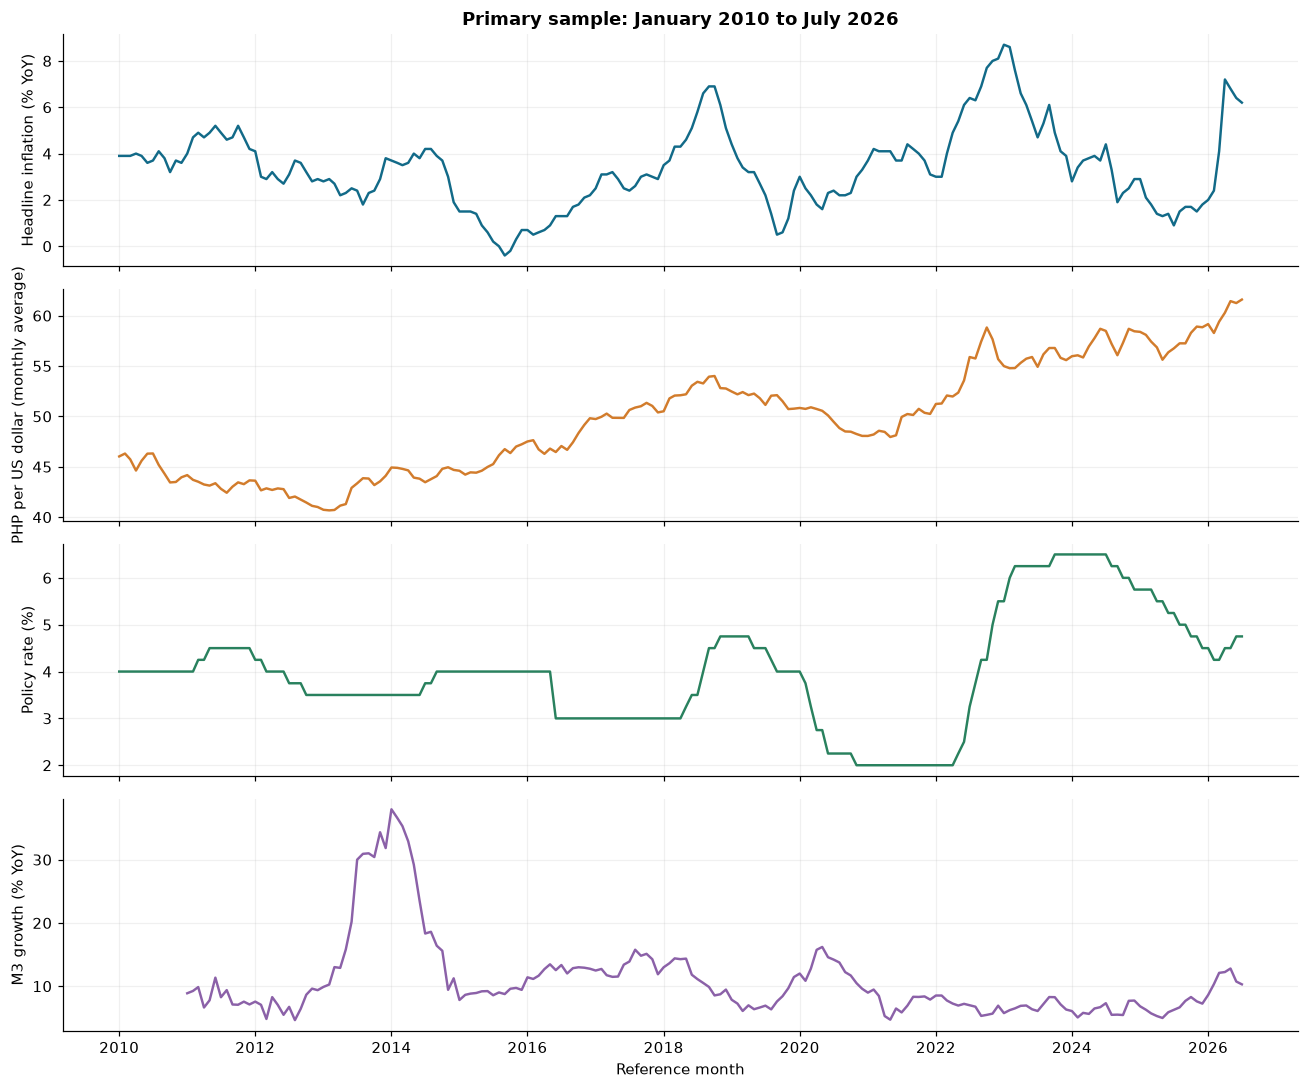

**Interpretation:** these series have different units and are shown separately. Inflation includes price-pressure episodes and low-inflation periods. Co-movement is not evidence of causality. M3 growth starts only after twelve prior level observations; missing growth is not replaced with zero.

In [3]:
fig,axes=plt.subplots(4,1,figsize=(12,10),sharex=True)
for ax,col,title,color in zip(axes,['inflation','exchange_rate','policy_rate','m3_growth'],
    ['Headline inflation (% YoY)','PHP per US dollar (monthly average)','Policy rate (%)','M3 growth (% YoY)'],COLORS):
    ax.plot(data.index,data[col],color=color,lw=1.6)
    ax.set_ylabel(title)
axes[0].set_title('Primary sample: January 2010 to July 2026')
axes[-1].set_xlabel('Reference month')
show_plot(fig,'01_series_history')
display(Markdown('**Interpretation:** these series have different units and are shown separately. Inflation includes price-pressure episodes and low-inflation periods. Co-movement is not evidence of causality. M3 growth starts only after twelve prior level observations; missing growth is not replaced with zero.'))

## 2. Experiment timeline and information availability
All candidates share the same effective sample and target-month blocks. M3 growth loses twelve starting months; the five-month target-relative predictor lag loses five more, so the common model sample starts June 2011.

For origin t and horizon h, use predictor month **t+h-5**. Even at h=3 this is t-2. This assumes predictor values are known within two months, which cannot be verified from the supplied files. Standardization is fitted separately on the training window. No interpolation, backward filling, random splitting or future predictor observations are used.

Origins are labeled by the last inflation reference month used, not a verified historical publication timestamp. Revised data remain a limitation.

Validation targets: 2023-08-01 00:00:00 to 2024-07-01 00:00:00
Final test targets: 2024-08-01 00:00:00 to 2026-07-01 00:00:00


,block,start,end,months
0,Initial development information,2011-06-01,2023-05-01,144
1,Validation target months,2023-08-01,2024-07-01,12
2,Previously evaluated holdout targets,2024-08-01,2026-07-01,24


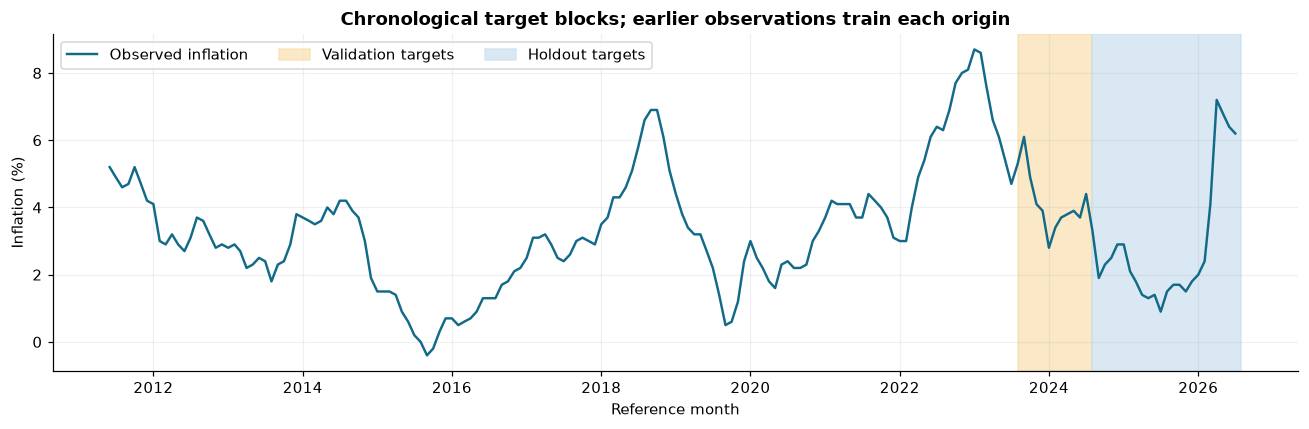

At each target, horizon-specific origins precede it by 1, 2 or 3 months. No split is shuffled.


In [4]:
features = ['exchange_rate','policy_rate','m3_growth']
# For target t+h, shift(5) uses predictor t+h-5, no later than origin-2.
X = data[features].shift(5)
start = X.dropna().index[0]
y = data.inflation.loc[start:]
X = X.loc[start:]
assert X.notna().all().all()
test_months = y.index[-24:]
validation_months = y.index[-36:-24]
print('Validation targets:',validation_months[0], 'to', validation_months[-1])
print('Final test targets:',test_months[0], 'to', test_months[-1])
development_end=validation_months[0]-pd.DateOffset(months=3)
development=y.loc[:development_end]
display(pd.DataFrame([
    {'block':'Initial development information','start':y.index[0],'end':development_end,'months':len(development)},
    {'block':'Validation target months','start':validation_months[0],'end':validation_months[-1],'months':len(validation_months)},
    {'block':'Previously evaluated holdout targets','start':test_months[0],'end':test_months[-1],'months':len(test_months)}]))
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(y.index,y,color=COLORS[0],lw=1.6,label='Observed inflation')
ax.axvspan(validation_months[0],validation_months[-1]+pd.offsets.MonthEnd(0),color='#f7d9a0',alpha=.6,label='Validation targets')
ax.axvspan(test_months[0],test_months[-1]+pd.offsets.MonthEnd(0),color='#c9dfee',alpha=.7,label='Holdout targets')
ax.set(title='Chronological target blocks; earlier observations train each origin',ylabel='Inflation (%)',xlabel='Reference month')
ax.legend(loc='upper left',ncol=3)
show_plot(fig,'02_experiment_timeline')
print('At each target, horizon-specific origins precede it by 1, 2 or 3 months. No split is shuffled.')

## 3. Training-only stationarity and lag diagnostics
The following diagnostics use information ending at the earliest validation origin. They describe the development data and do not retune the already evaluated experiment. ADF tests a unit-root null; rejecting that null does not prove model adequacy. Overlapping year-on-year rates can retain serial dependence even when stationary.

C:\Users\Luzan\AppData\Local\Temp\ipykernel_16288\1518205042.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series,autolag='AIC')
C:\Users\Luzan\AppData\Local\Temp\ipykernel_16288\1518205042.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series,autolag='AIC')


,series,ADF statistic,p value,selected lags,observations
0,Inflation level,-1.94755,0.31003,14,129
1,First difference,-3.15370,0.02283,13,129


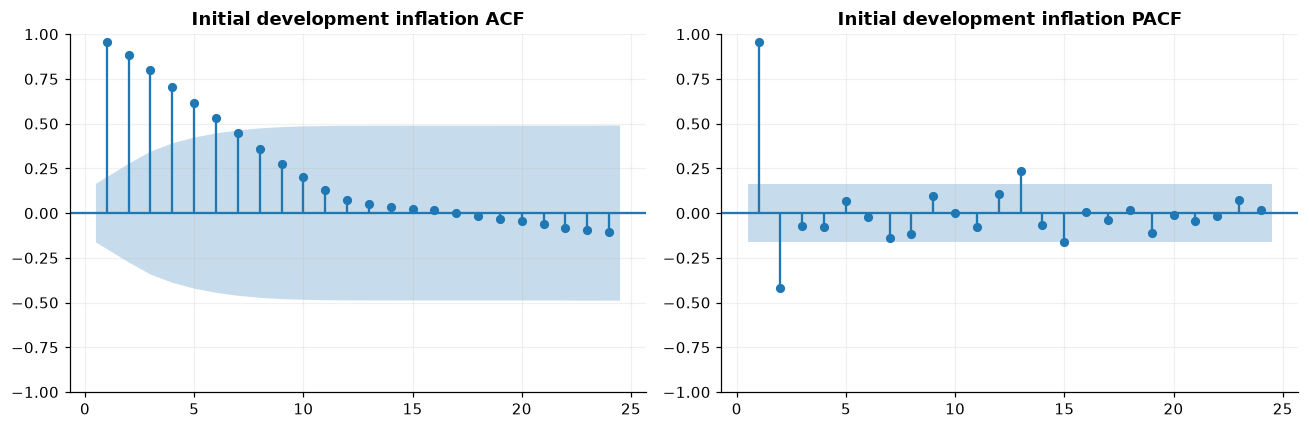

**Read the plots:** autocorrelation shows persistence across monthly lags. The seasonal period is 12 because observations are monthly. The fixed candidates below test a small AR/seasonal specification and a differenced alternative; this is not an exhaustive order search.

In [5]:
adf_rows=[]
for label,series in [('Inflation level',development),('First difference',development.diff().dropna())]:
    result=adfuller(series,autolag='AIC')
    adf_rows.append({'series':label,'ADF statistic':result[0],'p value':result[1],'selected lags':result[2],'observations':result[3]})
display(pd.DataFrame(adf_rows).round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4))
plot_acf(development,lags=24,ax=axes[0],zero=False)
plot_pacf(development,lags=24,ax=axes[1],zero=False,method='ywm')
axes[0].set_title('Initial development inflation ACF')
axes[1].set_title('Initial development inflation PACF')
show_plot(fig,'03_development_acf_pacf')
display(Markdown('**Read the plots:** autocorrelation shows persistence across monthly lags. The seasonal period is 12 because observations are monthly. The fixed candidates below test a small AR/seasonal specification and a differenced alternative; this is not an exhaustive order search.'))

## 4. Algorithms and fixed experimental settings
**Naive:** repeat the last observed inflation value. **Seasonal naive:** use the same month in the previous year. These are necessary reference points, not placeholder models.

**SARIMA(p,d,q)(P,D,Q,12):** p/q are nonseasonal AR/MA orders; d is differencing. P/D/Q are seasonal counterparts. Candidate A uses (1,0,0)(1,0,0,12); B changes d to 1. **SARIMAX** adds standardized, lagged economic predictors to candidate A. The single-indicator models test incremental information; the combined candidate uses all three.

Statistical fits include an intercept, use up to 150 optimizer iterations, and do not enforce stationarity/invertibility constraints. Convergence is checked; later residual diagnostics must still be assessed. AIC is descriptive, while actual selection uses validation RMSE averaged across the three horizons. Lower training error or a low AIC alone does not select the winner.

In [6]:
specs = {
 'Naive': {'family':'naive','features':[]},
 'Seasonal naive': {'family':'seasonal_naive','features':[]},
 'SARIMA A': {'family':'sarima','features':[], 'order':(1,0,0)},
 'SARIMA B': {'family':'sarima','features':[], 'order':(1,1,0)},
 'SARIMAX exchange': {'family':'sarimax','features':['exchange_rate'],'order':(1,0,0)},
 'SARIMAX policy': {'family':'sarimax','features':['policy_rate'],'order':(1,0,0)},
 'SARIMAX M3': {'family':'sarimax','features':['m3_growth'],'order':(1,0,0)},
 'SARIMAX combined': {'family':'sarimax','features':features,'order':(1,0,0)},
}
for spec in specs.values():
    spec.update(seasonal_order=(1,0,0,12),predictor_lag=5)

latest_fit = {}

def predict(name, origin):
    spec = specs[name]
    train = y.loc[:origin]
    dates = pd.date_range(origin+pd.offsets.MonthBegin(1),periods=3,freq='MS')
    if spec['family'] in ['naive','seasonal_naive']:
        values = [train.iloc[-1] if spec['family']=='naive' else train.loc[d-pd.DateOffset(years=1)] for d in dates]
        return np.array(values), None, {'converged':True,'interval':'unavailable for baseline'}
    cols = spec['features']
    xt = xf = None
    if cols:
        xt = X.loc[train.index,cols]
        mean, sd = xt.mean(), xt.std().replace(0,1)
        future = []
        for target in dates:
            source_month = target-pd.DateOffset(months=5)
            assert source_month <= origin-pd.DateOffset(months=2)
            future.append(data.loc[source_month,cols].values)
        xf = (pd.DataFrame(future,index=dates,columns=cols)-mean)/sd
        xt = (xt-mean)/sd
        assert xf.notna().all().all()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        fit = SARIMAX(train,exog=xt,order=spec['order'],seasonal_order=spec['seasonal_order'],
            trend='c',enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=150)
    latest_fit[name] = fit
    pred = fit.get_forecast(steps=3,exog=xf)
    residual = fit.resid.iloc[24:]
    diag = {'converged':bool(fit.mle_retvals.get('converged',False)), 'aic':float(fit.aic),
            'residual_mean':float(residual.mean()),
            'ljung_box_p_lag12':float(acorr_ljungbox(residual,lags=[12],return_df=True).lb_pvalue.iloc[0]),
            'warning_count':len(caught)}
    return np.asarray(pred.predicted_mean), np.asarray(pred.conf_int(alpha=.05)), diag

def evaluate(targets,phase):
    rows, runs = [], []
    for name in specs:
        # Cache per origin so overlapping horizons do not refit the same model.
        cache = {}
        for target in targets:
            for h in (1,2,3):
                origin = target-pd.DateOffset(months=h)
                if origin not in cache:
                    try:
                        cache[origin] = predict(name,origin)
                        runs.append({'model':name,'origin':str(origin.date()),'phase':phase,'status':'success',**cache[origin][2]})
                    except Exception as exc:
                        cache[origin] = None
                        runs.append({'model':name,'origin':str(origin.date()),'phase':phase,'status':'failed','error':str(exc)})
                result = cache[origin]
                if result is None:
                    continue
                values, interval, diag = result
                estimate = float(values[h-1])
                rows.append({'model':name,'phase':phase,'origin':str(origin.date()),'target':str(target.date()),
                    'horizon':h,'actual':float(y.loc[target]),'estimate':estimate,
                    'lower_95':None if interval is None else float(interval[h-1,0]),
                    'upper_95':None if interval is None else float(interval[h-1,1]),
                    'error':estimate-float(y.loc[target]),'converged':diag['converged']})
        print(phase,name,'complete',flush=True)
    return pd.DataFrame(rows), runs

def metrics(rows):
    return rows.groupby(['phase','model','horizon']).agg(
        MAE=('error',lambda s:float(s.abs().mean())),
        RMSE=('error',lambda s:float(np.sqrt(np.mean(s**2)))),N=('error','size')).reset_index()

In [7]:
specification_table=pd.DataFrame([{'model':name,'family':s['family'],
    'order':s.get('order','n/a'),'seasonal order':s['seasonal_order'] if 'order' in s else 'n/a',
    'predictors':', '.join(s['features']) or 'none','predictor lag':5 if s['features'] else 'n/a'} for name,s in specs.items()])
display(specification_table)
print('Forecast error = estimate - actual. Positive error means overprediction.')

,model,family,order,seasonal order,predictors,predictor lag
0,Naive,naive,n/a,n/a,none,n/a
1,Seasonal naive,seasonal_naive,n/a,n/a,none,n/a
2,SARIMA A,sarima,"(1, 0, 0)","(1, 0, 0, 12)",none,n/a
3,SARIMA B,sarima,"(1, 1, 0)","(1, 0, 0, 12)",none,n/a
4,SARIMAX exchange,sarimax,"(1, 0, 0)","(1, 0, 0, 12)",exchange_rate,5
5,SARIMAX policy,sarimax,"(1, 0, 0)","(1, 0, 0, 12)",policy_rate,5
6,SARIMAX M3,sarimax,"(1, 0, 0)","(1, 0, 0, 12)",m3_growth,5
7,SARIMAX combined,sarimax,"(1, 0, 0)","(1, 0, 0, 12)","exchange_rate, policy_rate, m3_growth",5


Forecast error = estimate - actual. Positive error means overprediction.


## 5. Expanding-origin validation and frozen selection
Each model produces 36 validation forecasts: twelve common target months at each of three horizons. The training window expands only through its origin. A candidate must supply all forecasts, finite values and convergence at every origin to qualify. Failures are exposed rather than replaced with a favorable fallback.

In [8]:
validation, validation_runs = evaluate(validation_months,'validation')
validation_metrics = metrics(validation)
eligible = []
for name in specs:
    r = validation[validation.model==name]
    if len(r)==36 and r.converged.all() and np.isfinite(r.estimate).all():
        eligible.append(name)
assert eligible, 'No complete converged validation candidate'
scores = validation_metrics[validation_metrics.model.isin(eligible)].groupby('model').RMSE.mean().sort_values()
winner = str(scores.index[0])
display(validation_metrics, scores)
print('Frozen model selection:',winner)

validation Naive complete


validation Seasonal naive complete


validation SARIMA A complete


validation SARIMA B complete


validation SARIMAX exchange complete


validation SARIMAX policy complete


validation SARIMAX M3 complete


validation SARIMAX combined complete


,phase,model,horizon,MAE,RMSE,N
0,validation,Naive,1,0.558333,0.666458,12
1,validation,Naive,2,0.733333,0.928260,12
2,validation,Naive,3,0.850000,1.080123,12
3,validation,SARIMA A,1,0.518973,0.595132,12
4,validation,SARIMA A,2,0.633438,0.810506,12
5,validation,SARIMA A,3,0.728185,0.891718,12
6,validation,SARIMA B,1,0.589742,0.703284,12
7,validation,SARIMA B,2,0.742024,1.047765,12
8,validation,SARIMA B,3,0.913922,1.173975,12
9,validation,SARIMAX M3,1,0.517508,0.595815,12


model
SARIMAX combined    0.737194
SARIMAX policy      0.740488
SARIMAX M3          0.763877
SARIMA A            0.765785
SARIMAX exchange    0.766764
Naive               0.891614
SARIMA B            0.975008
Seasonal naive      3.354723
Name: RMSE, dtype: float64

Frozen model selection: SARIMAX combined


,runs,failed,converged
model,,,
Naive,14,0,14
SARIMA A,14,0,14
SARIMA B,14,0,14
SARIMAX M3,14,0,14
SARIMAX combined,14,0,14
SARIMAX exchange,14,0,14
SARIMAX policy,14,0,14
Seasonal naive,14,0,14


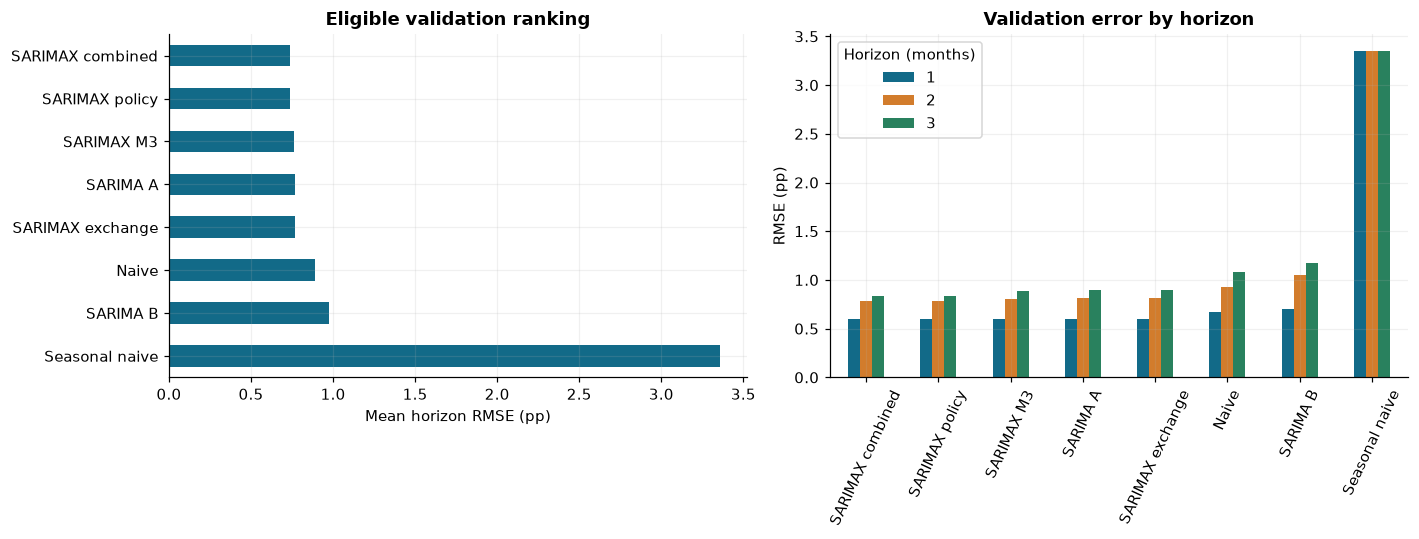

**Selection:** SARIMAX combined has the lowest mean validation-horizon RMSE among complete converged candidates (0.737 pp). The winner is fixed before reporting holdout results.

In [9]:
validation_audit=pd.DataFrame(validation_runs)
display(validation_audit.groupby('model').agg(runs=('status','size'),
    failed=('status',lambda s:int(s.ne('success').sum())),
    converged=('converged',lambda s:int(s.fillna(False).sum()))))
fig,axes=plt.subplots(1,2,figsize=(13,5))
scores.sort_values().plot.barh(ax=axes[0],color=COLORS[0])
axes[0].invert_yaxis()
axes[0].set(title='Eligible validation ranking',xlabel='Mean horizon RMSE (pp)',ylabel='')
validation_metrics.pivot(index='model',columns='horizon',values='RMSE').reindex(scores.index).plot.bar(ax=axes[1],color=COLORS[:3])
axes[1].set(title='Validation error by horizon',ylabel='RMSE (pp)',xlabel='')
axes[1].tick_params(axis='x',labelrotation=65)
axes[1].legend(title='Horizon (months)')
show_plot(fig,'04_validation_comparison')
display(Markdown(f'**Selection:** {winner} has the lowest mean validation-horizon RMSE among complete converged candidates ({scores.iloc[0]:.3f} pp). The winner is fixed before reporting holdout results.'))

## 6. Previously evaluated holdout: actual experimental results
The original specification is frozen. Earlier holdout observations may enter later expanding fits only after their origin has arrived. No new model, feature or order is chosen using this block. Because this block has been inspected before, do not label this run a fresh untouched test.

In [10]:
test, test_runs = evaluate(test_months,'test')
all_results = pd.concat([validation,test],ignore_index=True)
all_metrics = metrics(all_results)
display(all_metrics[all_metrics.phase=='test'])
for phase,expected in [('validation',12),('test',24)]:
    expected_grid=pd.MultiIndex.from_product([[phase],list(specs),[1,2,3]],names=['phase','model','horizon'])
    counts=all_results.groupby(['phase','model','horizon']).size().reindex(expected_grid,fill_value=0)
    assert counts.eq(expected).all(), counts[counts.ne(expected)].to_dict()
    sets=all_results[all_results.phase==phase].groupby(['model','horizon']).target.apply(lambda v:tuple(sorted(v)))
    assert len(set(sets))==1, 'Unmatched target months across competitors'
display(pd.DataFrame(test_runs).groupby('model').agg(runs=('status','size'),converged=('converged','sum')))
all_results.to_csv(OUT/'backtest.csv',index=False)
all_metrics.to_csv(OUT/'metrics.csv',index=False)
(OUT/'runs.json').write_text(json.dumps(validation_runs+test_runs,indent=2))

test Naive complete


test Seasonal naive complete


test SARIMA A complete


test SARIMA B complete


test SARIMAX exchange complete


test SARIMAX policy complete


test SARIMAX M3 complete


test SARIMAX combined complete


,phase,model,horizon,MAE,RMSE,N
0,test,Naive,1,0.558333,0.872735,24
1,test,Naive,2,0.937500,1.416127,24
2,test,Naive,3,1.225000,1.759972,24
3,test,SARIMA A,1,0.477190,0.775621,24
4,test,SARIMA A,2,0.798834,1.246232,24
5,test,SARIMA A,3,1.129917,1.559990,24
6,test,SARIMA B,1,0.507269,0.784945,24
7,test,SARIMA B,2,0.807192,1.339498,24
8,test,SARIMA B,3,1.152605,1.698155,24
9,test,SARIMAX M3,1,0.477911,0.776173,24


,runs,converged
model,,
Naive,26,26
SARIMA A,26,26
SARIMA B,26,26
SARIMAX M3,26,26
SARIMAX combined,26,25
SARIMAX exchange,26,25
SARIMAX policy,26,25
Seasonal naive,26,26


81794

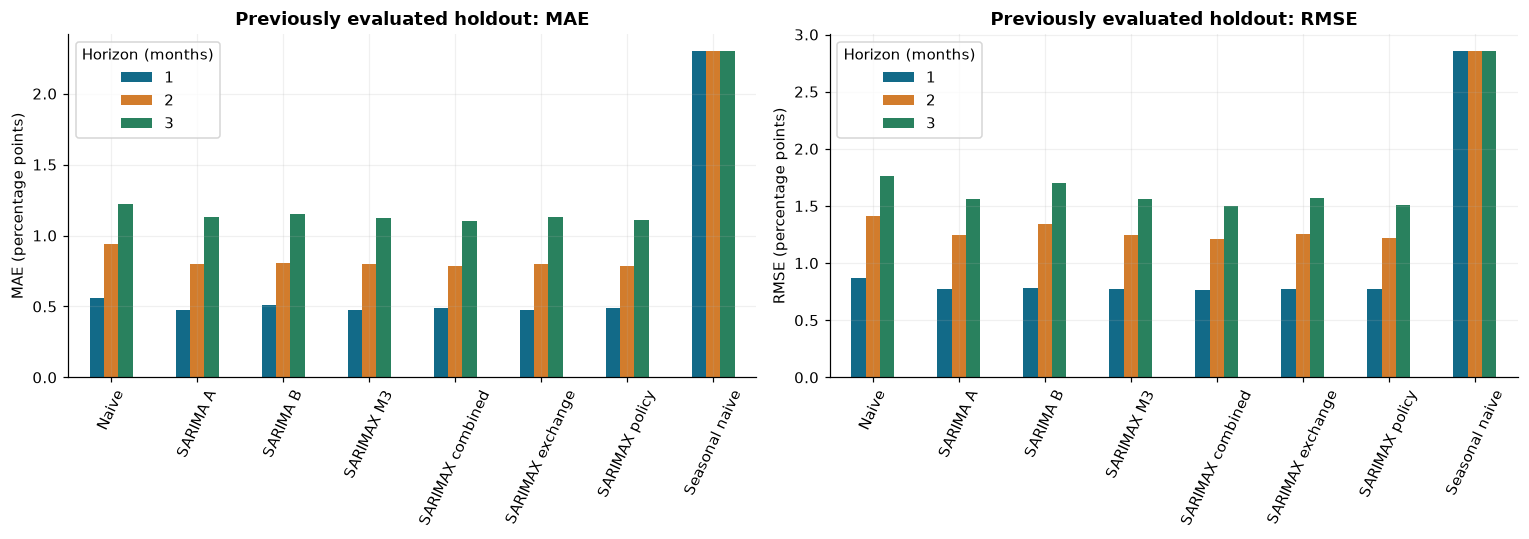

model,Naive,SARIMA A,SARIMAX combined,RMSE reduction vs naive (%)
horizon,,,,
1,0.8727,0.7756,0.7674,12.0701
2,1.4161,1.2462,1.2114,14.4550
3,1.7600,1.5600,1.5019,14.6611


**Interpretation:** MAE is average absolute error in percentage points. RMSE gives greater weight to large misses. Compare models only on matching targets and horizons. Improvement in this supplied vintage is not proof of causal influence or guaranteed future performance.

In [11]:
test_metrics=all_metrics[all_metrics.phase=='test']
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,metric in zip(axes,['MAE','RMSE']):
    test_metrics.pivot(index='model',columns='horizon',values=metric).plot.bar(ax=ax,color=COLORS[:3])
    ax.set(title=f'Previously evaluated holdout: {metric}',ylabel=f'{metric} (percentage points)',xlabel='')
    ax.tick_params(axis='x',labelrotation=65)
    ax.legend(title='Horizon (months)')
show_plot(fig,'05_holdout_model_comparison')
selected_test=test[test.model==winner].copy()
comparison=test_metrics[test_metrics.model.isin([winner,'Naive','SARIMA A'])].pivot(index='horizon',columns='model',values='RMSE')
comparison['RMSE reduction vs naive (%)']=100*(comparison['Naive']-comparison[winner])/comparison['Naive']
display(comparison.round(4))
display(Markdown('**Interpretation:** MAE is average absolute error in percentage points. RMSE gives greater weight to large misses. Compare models only on matching targets and horizons. Improvement in this supplied vintage is not proof of causal influence or guaranteed future performance.'))

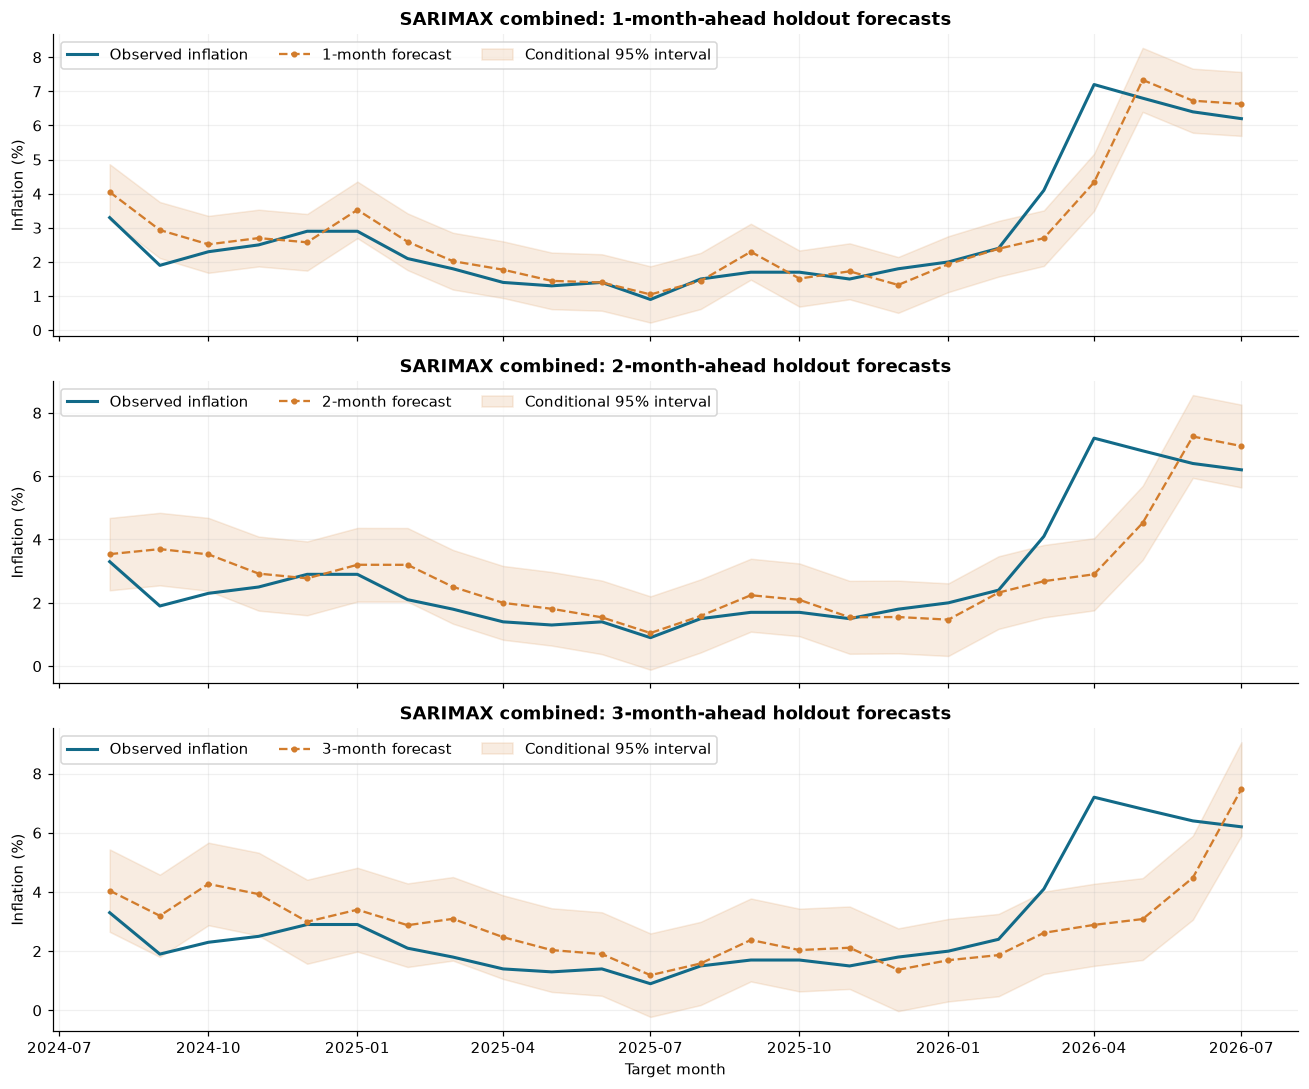

,origin,target,horizon,actual,estimate,error
564,2026-03-01,2026-04-01,1,7.2,4.3332,-2.8668
565,2026-02-01,2026-04-01,2,7.2,2.9013,-4.2987
566,2026-01-01,2026-04-01,3,7.2,2.8880,-4.3120
567,2026-04-01,2026-05-01,1,6.8,7.3354,0.5354
568,2026-03-01,2026-05-01,2,6.8,4.5224,-2.2776
569,2026-02-01,2026-05-01,3,6.8,3.0841,-3.7159
570,2026-05-01,2026-06-01,1,6.4,6.7258,0.3258
571,2026-04-01,2026-06-01,2,6.4,7.2522,0.8522
572,2026-03-01,2026-06-01,3,6.4,4.4790,-1.9210
573,2026-06-01,2026-07-01,1,6.2,6.6317,0.4317


**Read the plot:** forecast misses can increase around rapid changes in inflation. The forecast line was generated from an earlier origin for each horizon, not fitted using the displayed target value. Conditional intervals do not include all parameter or data-revision uncertainty.

In [12]:
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
for h,ax in zip([1,2,3],axes):
    rows=selected_test[selected_test.horizon==h].sort_values('target')
    dates=pd.to_datetime(rows.target)
    ax.plot(dates,rows.actual,label='Observed inflation',color=COLORS[0],lw=2)
    ax.plot(dates,rows.estimate,label=f'{h}-month forecast',color=COLORS[1],ls='--',marker='o',ms=3)
    if rows.lower_95.notna().all():
        ax.fill_between(dates,rows.lower_95,rows.upper_95,color=COLORS[1],alpha=.14,label='Conditional 95% interval')
    ax.set(title=f'{winner}: {h}-month-ahead holdout forecasts',ylabel='Inflation (%)')
    ax.legend(loc='upper left',ncol=3)
axes[-1].set_xlabel('Target month')
show_plot(fig,'06_actual_vs_predicted')
display(selected_test[['origin','target','horizon','actual','estimate','error']].tail(12).round(4))
display(Markdown('**Read the plot:** forecast misses can increase around rapid changes in inflation. The forecast line was generated from an earlier origin for each horizon, not fitted using the displayed target value. Conditional intervals do not include all parameter or data-revision uncertainty.'))

,N,bias,MAE,RMSE,converged_forecasts,conditional_interval_coverage
horizon,,,,,,
1,24,0.0389,0.4882,0.7674,23,0.8750
2,24,0.0368,0.7848,1.2114,23,0.7917
3,24,0.0413,1.0994,1.5019,23,0.7500


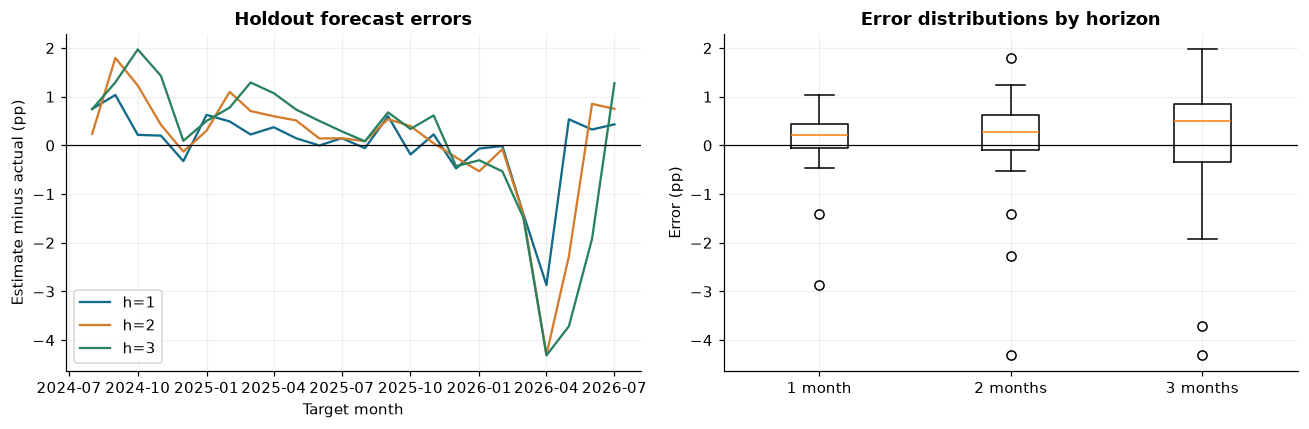

**Interpretation:** positive bias indicates average overprediction; negative bias indicates underprediction. Coverage is an empirical descriptive fraction from only 24 targets per horizon. Forecast errors overlap across horizons and origins, so these observations are not independent trials.

In [13]:
error_summary=selected_test.groupby('horizon').agg(
    N=('error','size'),bias=('error','mean'),MAE=('error',lambda s:s.abs().mean()),
    RMSE=('error',lambda s:np.sqrt(np.mean(s**2))),converged_forecasts=('converged','sum'))
selected_test['covered_95']=(selected_test.actual>=selected_test.lower_95)&(selected_test.actual<=selected_test.upper_95)
if selected_test.lower_95.notna().all():
    error_summary['conditional_interval_coverage']=selected_test.groupby('horizon').covered_95.mean()
display(error_summary.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for h,color in zip([1,2,3],COLORS):
    rows=selected_test[selected_test.horizon==h].sort_values('target')
    axes[0].plot(pd.to_datetime(rows.target),rows.error,label=f'h={h}',color=color)
axes[0].axhline(0,color='black',lw=.8)
axes[0].set(title='Holdout forecast errors',ylabel='Estimate minus actual (pp)',xlabel='Target month')
axes[0].legend()
axes[1].boxplot([selected_test.loc[selected_test.horizon==h,'error'] for h in [1,2,3]],tick_labels=['1 month','2 months','3 months'])
axes[1].axhline(0,color='black',lw=.8)
axes[1].set(title='Error distributions by horizon',ylabel='Error (pp)')
show_plot(fig,'07_forecast_errors')
display(Markdown('**Interpretation:** positive bias indicates average overprediction; negative bias indicates underprediction. Coverage is an empirical descriptive fraction from only 24 targets per horizon. Forecast errors overlap across horizons and origins, so these observations are not independent trials.'))

## 7. Selected-model refit and three-month forecast
Refit the frozen validation winner using inflation through July 2026. Generate August-October 2026 estimates and conditional 95% intervals. August's supplied actual is available only for an explicitly separated later comparison. There are no invented actuals for later months.

In [14]:
origin = y.index[-1]
values, interval, diagnostics = predict(winner,origin)
assert diagnostics['converged'], 'Selected production fit did not converge'
forecast = pd.DataFrame({'target':pd.date_range(origin+pd.offsets.MonthBegin(1),periods=3,freq='MS'),
    'horizon':[1,2,3],'estimate':values,
    'lower_95':np.nan if interval is None else interval[:,0],
    'upper_95':np.nan if interval is None else interval[:,1]})
forecast.to_csv(OUT/'forecast.csv',index=False)
metadata = {'selected_model':winner,'forecast_origin':str(origin.date()),'training_start':str(y.index[0].date()),
 'validation_start':str(validation_months[0].date()),'validation_end':str(validation_months[-1].date()),
 'test_start':str(test_months[0].date()),'test_end':str(test_months[-1].date()),
 'selection':'Mean validation horizon RMSE; complete converged candidates only',
 'predictor_lag_months':5,'availability':'Retrospective; release dates unavailable; assumes predictors known after two months',
 'eligible_candidates':eligible,'specifications':specs,'production_diagnostics':diagnostics}
(OUT/'model.json').write_text(json.dumps(metadata,indent=2))
review_fit=latest_fit.get(winner)
display(forecast.round(4))
print(json.dumps(diagnostics,indent=2))

C:\Users\Luzan\AppData\Local\Temp\ipykernel_16288\366758146.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast.round(4))


,target,horizon,estimate,lower_95,upper_95
0,2026-08-01,1,5.9444,5.0076,6.8812
1,2026-09-01,2,5.8117,4.5088,7.1146
2,2026-10-01,3,5.8300,4.2604,7.3996


{
  "converged": true,
  "aic": 244.09319603535064,
  "residual_mean": 0.0063496101013439865,
  "ljung_box_p_lag12": 0.004458434727329937,
  "warning_count": 0
}


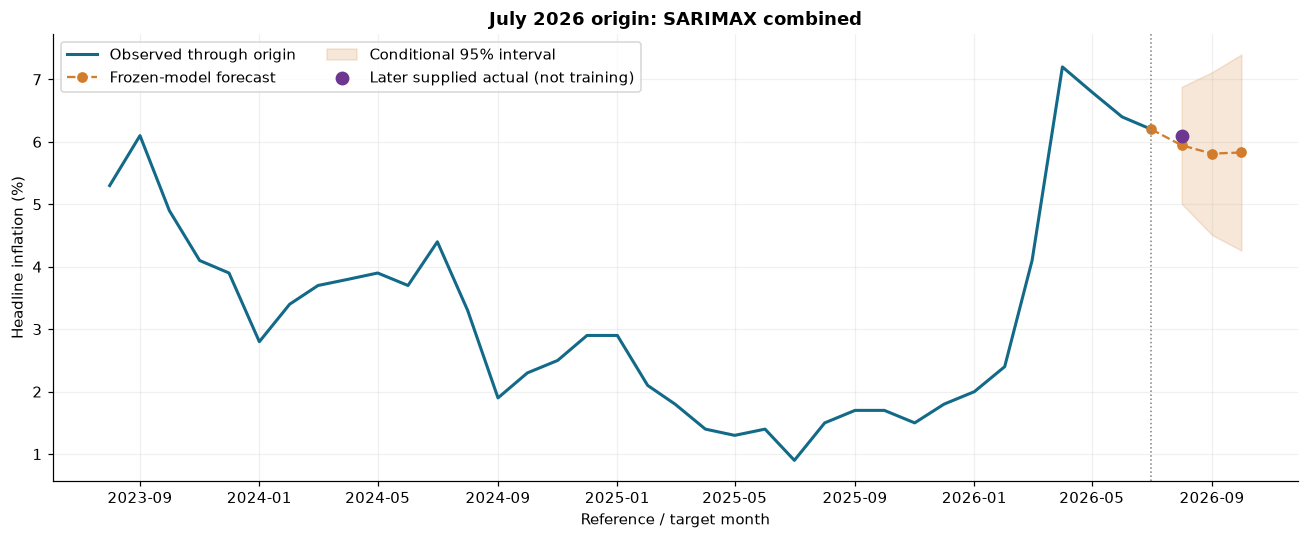

,forecast,later_supplied_actual
target,,
2026-08-01,5.944432,6.1
2026-09-01,5.811657,NaN
2026-10-01,5.829998,NaN


**Forecast interpretation:** from the origin value of 6.2%, the model estimates 5.94% for August 2026, 5.81% for September 2026, 5.83% for October 2026. These are provisional analytical estimates; residual diagnostics below determine whether the specification is adequate.

In [15]:
fig,ax=plt.subplots(figsize=(12,5))
history=y.iloc[-36:]
ax.plot(history.index,history,label='Observed through origin',color=COLORS[0],lw=2)
ax.plot([origin,*forecast.target],[y.iloc[-1],*forecast.estimate],label='Frozen-model forecast',color=COLORS[1],ls='--',marker='o')
if forecast.lower_95.notna().all():
    ax.fill_between(forecast.target,forecast.lower_95,forecast.upper_95,color=COLORS[1],alpha=.18,label='Conditional 95% interval')
later=monthly.loc[monthly.index>origin,'inflation'].dropna().reindex(forecast.target).dropna()
ax.scatter(later.index,later.values,label='Later supplied actual (not training)',color='#6d3791',s=65,zorder=5)
ax.axvline(origin,color='grey',ls=':',lw=1)
ax.set(title=f'July 2026 origin: {winner}',ylabel='Headline inflation (%)',xlabel='Reference / target month')
ax.legend(loc='upper left',ncol=2)
show_plot(fig,'08_three_month_forecast')
display(pd.DataFrame({'forecast':forecast.set_index('target').estimate,'later_supplied_actual':later}))
display(Markdown(f'**Forecast interpretation:** from the origin value of {y.iloc[-1]:.1f}%, the model estimates '+', '.join(f'{r.estimate:.2f}% for {r.target:%B %Y}' for r in forecast.itertuples())+'. These are provisional analytical estimates; residual diagnostics below determine whether the specification is adequate.'))

## 8. Model adequacy: coefficients, residuals and autocorrelation
Optimizer convergence only means the fitting routine stopped successfully. It does not mean errors are white noise or the specification is reliable. Coefficients on standardized lagged predictors are conditional associations, not causal effects or a separate feature-importance ranking.

For residual review, discard at least 24 starting observations and the model's likelihood burn-in. Ljung-Box p-values below use an AR/MA degrees-of-freedom adjustment (p+q+P+Q). They are descriptive checks on a refit after selection, not extra holdout evidence.

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                          inflation   No. Observations:                  182
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                -115.047
Date:                            Sat, 31 Oct 2026   AIC                            244.093
Time:                                    00:06:31   BIC                            266.002
Sample:                                06-01-2011   HQIC                           252.984
                                     - 07-01-2026                                         
Covariance Type:                              opg                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
intercept         0.1615      0.153      1.058      0.290      -0.138       0.461
exchange_rate     0.5032      0.267      1.883      0.060      -0.021       1.027
policy_rate      -0.5228      0.311     -1.679      0.093      -1.133       0.088
m3_growth         0.0458      0.145      0.315      0.753      -0.239       0.331
ar.L1             0.9666      0.027     35.852      0.000       0.914       1.019
ar.S.L12         -0.5063      0.075     -6.796      0.000      -0.652      -0.360
sigma2            0.2285      0.019     12.282      0.000       0.192       0.265
===================================================================================
Ljung-Box (L1) (Q):                  18.01   Jarque-Bera (JB):               267.73
Prob(Q):                              0.00   Prob(JB):                         0.00
Heteroskedasticity (H):               4.46   Skew:                             1.32
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.57
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

,coefficient,std_error,p_value,lower_95,upper_95
intercept,0.16153,0.15273,0.29024,-0.13782,0.46088
exchange_rate,0.50319,0.26728,0.05975,-0.02067,1.02705
policy_rate,-0.52281,0.31144,0.09321,-1.13321,0.08759
m3_growth,0.04583,0.14546,0.75270,-0.23927,0.33093
ar.L1,0.96657,0.02696,0.00000,0.91373,1.01941
ar.S.L12,-0.50634,0.07451,0.00000,-0.65237,-0.36031
sigma2,0.22846,0.01860,0.00000,0.19200,0.26492


,lb_stat,lb_pvalue
6,19.453747,0.000640
12,28.637458,0.001426
18,31.843614,0.010479
24,51.232428,0.000399


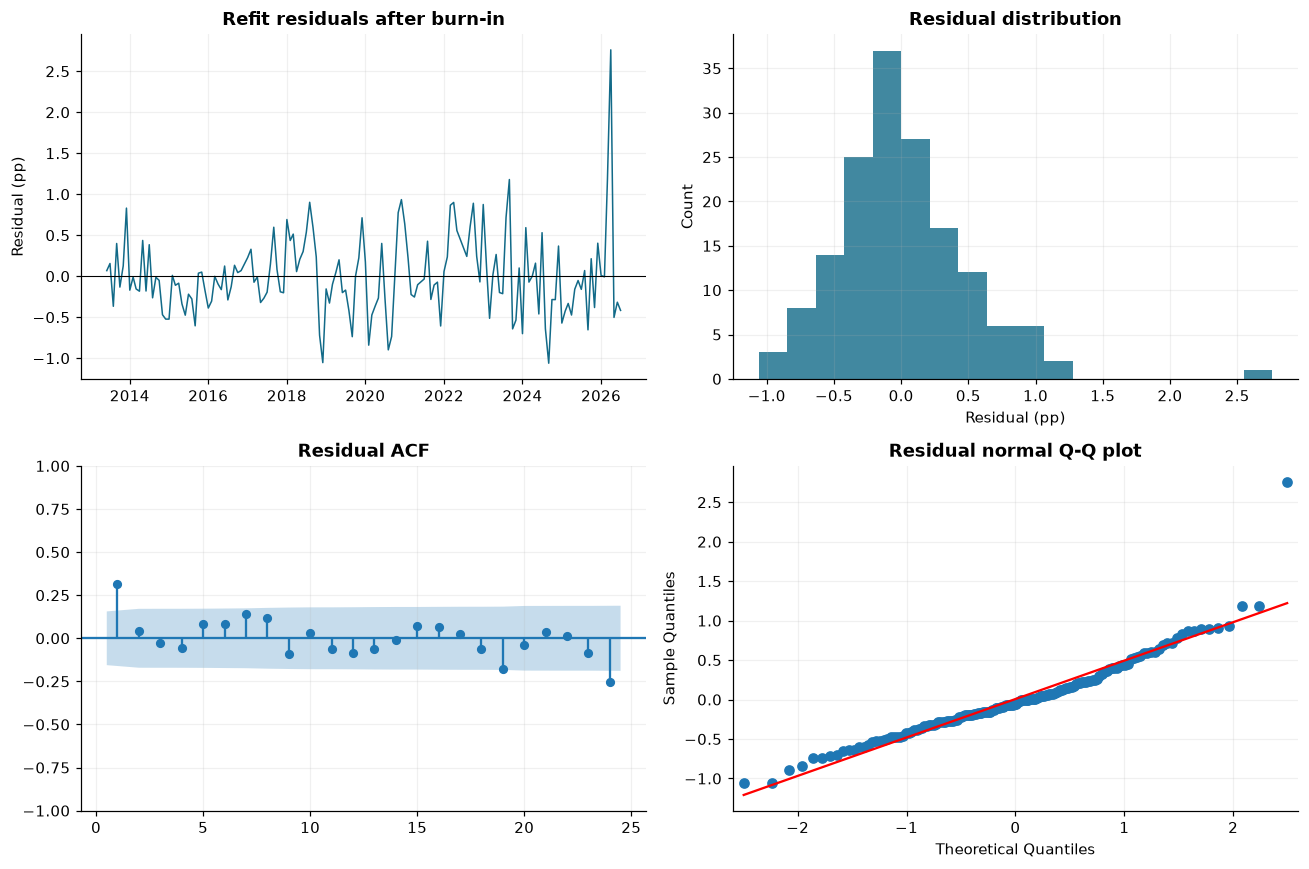

**Adequacy review:** Residual autocorrelation remains at one or more inspected lags. Treat the selected model as provisional: it wins this validation comparison but does not pass full residual adequacy review.

Adjusted Ljung-Box model_df: 2 ; residual burn-in: 24


In [16]:
if review_fit is None:
    display(Markdown('The selected baseline has no fitted SARIMA residual or coefficient diagnostics.'))
else:
    display(review_fit.summary())
    bounds=review_fit.conf_int()
    coefficient_table=pd.DataFrame({'coefficient':review_fit.params,'std_error':review_fit.bse,'p_value':review_fit.pvalues,
        'lower_95':bounds.iloc[:,0],'upper_95':bounds.iloc[:,1]})
    display(coefficient_table.round(5))
    coefficient_table.to_csv(OUT/'selected_coefficients.csv')
    burn=max(24,int(review_fit.loglikelihood_burn))
    residual=review_fit.resid.iloc[burn:].dropna()
    specification=specs[winner]
    model_df=sum([specification['order'][0],specification['order'][2],specification['seasonal_order'][0],specification['seasonal_order'][2]])
    lb=acorr_ljungbox(residual,lags=[6,12,18,24],model_df=model_df,return_df=True)
    display(lb)
    lb.to_csv(OUT/'ljung_box.csv')
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    axes[0,0].plot(residual.index,residual,color=COLORS[0],lw=1)
    axes[0,0].axhline(0,color='black',lw=.7)
    axes[0,0].set(title='Refit residuals after burn-in',ylabel='Residual (pp)')
    axes[0,1].hist(residual,bins=18,color=COLORS[0],alpha=.8)
    axes[0,1].set(title='Residual distribution',xlabel='Residual (pp)',ylabel='Count')
    plot_acf(residual,lags=24,zero=False,ax=axes[1,0])
    axes[1,0].set_title('Residual ACF')
    qqplot(residual,line='s',ax=axes[1,1])
    axes[1,1].set_title('Residual normal Q-Q plot')
    show_plot(fig,'09_residual_diagnostics')
    adequate=bool(lb.lb_pvalue.gt(.05).all())
    display(Markdown('**Adequacy review:** '+('No listed Ljung-Box check rejects the no-autocorrelation null at 5%; this is not proof of adequacy.' if adequate else 'Residual autocorrelation remains at one or more inspected lags. Treat the selected model as provisional: it wins this validation comparison but does not pass full residual adequacy review.')))
    print('Adjusted Ljung-Box model_df:',model_df,'; residual burn-in:',burn)

## 9. Future-information perturbation check
At one historical origin, replace later inflation and predictor records with extreme values, then recompute the same forecast. It must be unchanged. Restore the original data immediately. This tests the implemented information boundary; it does not authenticate publication dates or remove historical revisions.

In [17]:
audit_origin=test_months[0]-pd.DateOffset(months=3)
before=predict(winner,audit_origin)[0]
saved_data,saved_y,saved_X=data.copy(deep=True),y.copy(deep=True),X.copy(deep=True)
try:
    data.loc[data.index>audit_origin,:]=1e6
    y.loc[y.index>audit_origin]=1e6
    X.loc[X.index>audit_origin,:]=1e6
    after=predict(winner,audit_origin)[0]
    assert np.allclose(before,after,atol=1e-7,rtol=1e-7), 'Future-information leakage detected'
finally:
    data,y,X=saved_data,saved_y,saved_X
display(pd.DataFrame({'horizon':[1,2,3],'before_future_perturbation':before,'after_future_perturbation':after,'difference':after-before}))
print('PASS: later input changes did not alter forecasts at the historical origin.')

,horizon,before_future_perturbation,after_future_perturbation,difference
0,1,4.200843,4.200843,0.0
1,2,4.398941,4.398941,0.0
2,3,4.044841,4.044841,0.0


PASS: later input changes did not alter forecasts at the historical origin.


## 10. Review conclusion and demonstration discussion
**What is implemented:** a reproducible monthly dataset audit; eight explained benchmarks/statistical candidates; expanding-origin validation at three horizons; frozen validation selection; per-horizon holdout metrics and plots; a three-month forecast; fitted-model/residual diagnostics; and a future-input invariance check.

**What is not established:** official data authentication, true real-time publication availability, robustness across historical vintages, causal economic effects, broad predictor stability, or deployment readiness. Residual adequacy must be assessed separately from convergence and validation rank.

**Suggested oral walkthrough:**
1. Explain the target, units, source files, monthly grain and 199-month primary sample.
2. Explain missing markers, M3 growth, policy carry-forward and the common effective model sample.
3. Demonstrate the origin/target/lag rule with one horizon; explain why there is no random split.
4. Explain SARIMA orders, SARIMAX predictors, naive benchmarks and validation-only selection.
5. Read actual plotted errors and MAE/RMSE values in percentage points, then discuss residual weaknesses.
6. Explain why the already reviewed holdout cannot be reused for repeated tuning and what new evaluation would be needed.

Each member should be able to run cells and explain their purpose. This notebook supplies evidence of progress; it cannot substitute for each member's understanding.

In [18]:
summary=test_metrics[test_metrics.model==winner][['horizon','MAE','RMSE','N']].copy()
display(summary.round(4))
review_status={'winner':winner,'candidate_count':len(specs),'primary_months':len(data),
    'effective_months':len(y),'validation_targets_per_horizon':len(validation_months),'holdout_targets_per_horizon':len(test_months),
    'holdout_status':'Previously evaluated; not a new untouched assessment',
    'adequacy':'Review residual diagnostics; validation winner is not proof of adequacy',
    'web_app_used':False,'database_used':False}
(OUT/'review_summary.json').write_text(json.dumps(review_status,indent=2))
print(json.dumps(review_status,indent=2))
print('All outputs are notebook-only review artifacts. Existing app artifacts were not overwritten.')

,horizon,MAE,RMSE,N
12,1,0.4882,0.7674,24
13,2,0.7848,1.2114,24
14,3,1.0994,1.5019,24


{
  "winner": "SARIMAX combined",
  "candidate_count": 8,
  "primary_months": 199,
  "effective_months": 182,
  "validation_targets_per_horizon": 12,
  "holdout_targets_per_horizon": 24,
  "holdout_status": "Previously evaluated; not a new untouched assessment",
  "adequacy": "Review residual diagnostics; validation winner is not proof of adequacy",
  "web_app_used": false,
  "database_used": false
}
All outputs are notebook-only review artifacts. Existing app artifacts were not overwritten.
